In [1]:
# Run from the repo root so relative data/ paths resolve, wherever the notebook is launched.
import os
for _ in range(6):
    if os.path.exists('pyproject.toml'):
        break
    os.chdir('..')


# OOS Forecast Plots — Target Beta & VW-MSE

Out-of-sample (2015–2024) forecasts of 12-month-forward realized beta from the **LSTM**
and the two rolling-OLS benchmarks (**OLS_1Y_D**, **OLS_5Y_M**).

- **Figure 1** — monthly value-weighted cross-sectional mean beta: realized vs. each model's forecast.
- **Figure 2** — monthly value-weighted MSE (VW-MSE) of each model.

Both panels are value-weighted (weights = market cap = `exp(ME)`) for consistency.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

oos = pd.read_parquet("data/processed/oos_forecasts.parquet")
vw_mse = pd.read_parquet("data/processed/monthly_vw_mse.parquet")

oos["date"] = pd.to_datetime(oos["date"])
print(oos.shape, "OOS samples |", oos["ym"].nunique(), "months |", oos["ric"].nunique(), "stocks")

(10145, 9) OOS samples | 120 months | 170 stocks


## Figure 1 — Target beta: realized vs. forecasts (monthly VW mean)

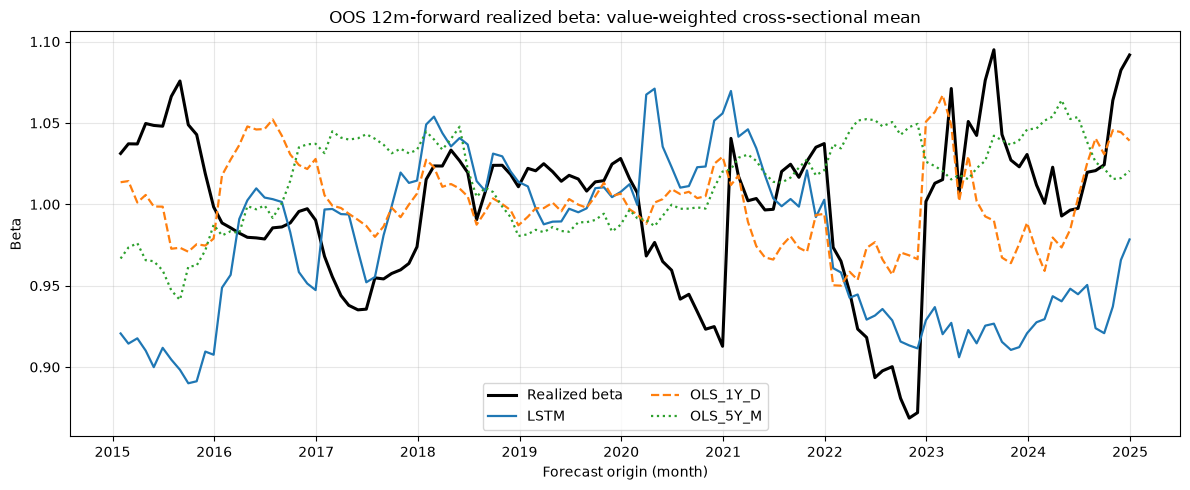

In [3]:
def vw_mean(g, col):
    w = np.exp(g["ME"].to_numpy())
    return np.average(g[col].to_numpy(), weights=w)

cols = {"y_true": "Realized beta", "yhat_lstm": "LSTM",
        "yhat_ols1yd": "OLS_1Y_D", "yhat_ols5ym": "OLS_5Y_M"}

beta_ts = (oos.groupby("date")
              .apply(lambda g: pd.Series({name: vw_mean(g, c) for c, name in cols.items()}))
              .sort_index())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(beta_ts.index, beta_ts["Realized beta"], color="black", lw=2.2, label="Realized beta")
for name, style in [("LSTM", "-"), ("OLS_1Y_D", "--"), ("OLS_5Y_M", ":")]:
    ax.plot(beta_ts.index, beta_ts[name], style, lw=1.6, label=name)
ax.set_title("OOS 12m-forward realized beta: value-weighted cross-sectional mean")
ax.set_xlabel("Forecast origin (month)")
ax.set_ylabel("Beta")
ax.legend(loc="best", ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/fig_oos_beta_timeseries.png", dpi=150)
plt.show()

## Figure 2 — Monthly VW-MSE by model

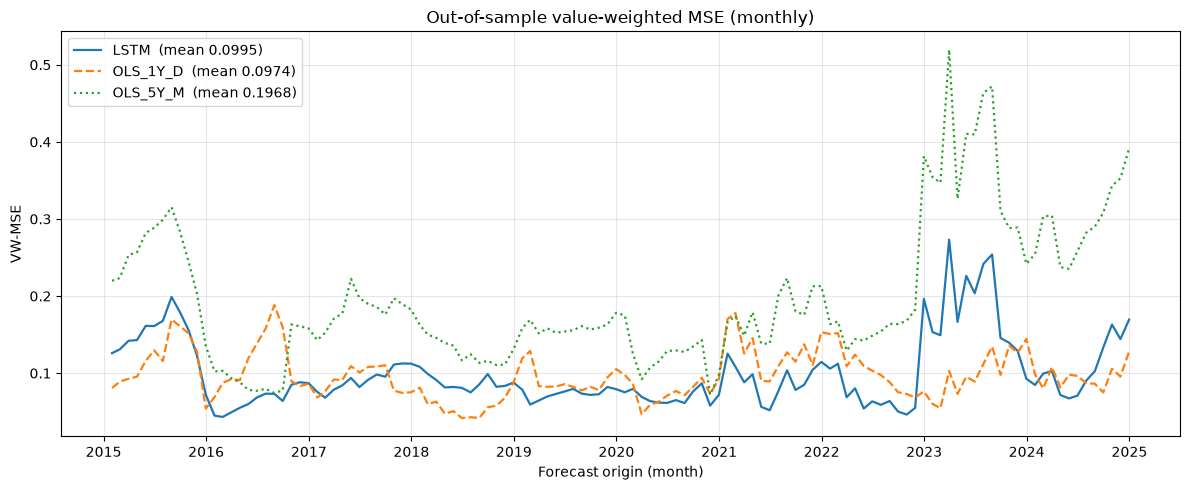

In [4]:
vw = vw_mse.copy()
vw.index = pd.PeriodIndex(vw.index, freq="M").to_timestamp(how="end").normalize()

fig, ax = plt.subplots(figsize=(12, 5))
for name, style in [("LSTM", "-"), ("OLS_1Y_D", "--"), ("OLS_5Y_M", ":")]:
    ax.plot(vw.index, vw[name], style, lw=1.6, label=f"{name}  (mean {vw[name].mean():.4f})")
ax.set_title("Out-of-sample value-weighted MSE (monthly)")
ax.set_xlabel("Forecast origin (month)")
ax.set_ylabel("VW-MSE")
ax.legend(loc="best")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/fig_oos_vwmse_timeseries.png", dpi=150)
plt.show()